# Chi-Square Goodness-of-Fit Test — Student ID 41
Class Performance Test 5 | Significance level: 5%

## Import Necessary Libraries

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

## 1. My Student ID's last two digits: **41**

##2: Observed Data

In [2]:
d = 41

a = 20 + d         # C
b = 25 + (d % 10)  # C++
c = 30 + (d % 7)   # Java
e = 35 + (d % 5)   # Python
observed = np.array([a, b, c, e])

print("My ID's last two digits:", d)
for language, frequency in zip(["C", "C++", "Java", "Python"], observed):
    print(f"{language}: {frequency}")
print("Observed (O):", observed)

My ID's last two digits: 41
C: 61
C++: 26
Java: 36
Python: 36
Observed (O): [61 26 36 36]


## 3–4. Null and Alternative Hypotheses

- **H₀:** Students have equal preferences for all four programming languages (25% each).
- **H₁:** Preferences are not equal across all four languages (at least one proportion differs).

## 5. Expected Frequencies for Each Category

In [3]:
total = np.sum(observed)
expected = np.full(len(observed), total / len(observed), dtype=float)
print(f'Total responses: {total}')
print(f'Expected frequency per language: {total / len(observed):.2f}')
print(f'Expected frequencies: {expected}')

Total responses: 159
Expected frequency per language: 39.75
Expected frequencies: [39.75 39.75 39.75 39.75]


## 6. Chi-Square Statistic Calculation

Formula: $\chi^2 = \sum \frac{(O-E)^2}{E}$.

In [4]:
chi_square_contributions = ((observed - expected) ** 2) / expected
chi_square_stat = np.sum(chi_square_contributions)
for language, contribution in zip(["C", "C++", "Java", "Python"], chi_square_contributions):
    print(f"{language}: {contribution:.4f}")
print(f'Calculated chi-square: {chi_square_stat:.4f}')

C: 11.3601
C++: 4.7563
Java: 0.3538
Python: 0.3538
Calculated chi-square: 16.8239


## 7. Degrees of Freedom

In [5]:
df = len(observed) - 1
print(f'Degrees of freedom: {df}')

Degrees of freedom: 3


## 8. Critical Value and p-Value

In [6]:
alpha = 0.05
critical_value = stats.chi2.ppf(1 - alpha, df)
p_value = stats.chi2.sf(chi_square_stat, df)
print(f'Significance level: {alpha:.2f}')
print(f'Critical value: {critical_value:.4f}')
print(f'p-value: {p_value:.6f}')

Significance level: 0.05
Critical value: 7.8147
p-value: 0.000768


## 9. Final Decision

In [7]:
print(f'Chi-square statistic: {chi_square_stat:.4f}')
print(f'Degrees of freedom: {df}')
print(f'Critical value (5% significance): {critical_value:.4f}')
print(f'p-value: {p_value:.6f}')
if chi_square_stat > critical_value:
    print('Decision: Reject H0.')
else:
    print('Decision: Fail to reject H0.')

Chi-square statistic: 16.8239
Degrees of freedom: 3
Critical value (5% significance): 7.8147
p-value: 0.000768
Decision: Reject H0.


## 10. Conclusion in the Scenario Context

In [8]:
if p_value < alpha:
    print('At the 5% significance level, there is sufficient evidence that students')
    print('do not have equal preferences for C, C++, Java, and Python.')
else:
    print('At the 5% significance level, there is insufficient evidence that students')
    print('have unequal preferences for C, C++, Java, and Python.')

At the 5% significance level, there is sufficient evidence that students
do not have equal preferences for C, C++, Java, and Python.


## Observed vs Expected Frequencies (Graph)

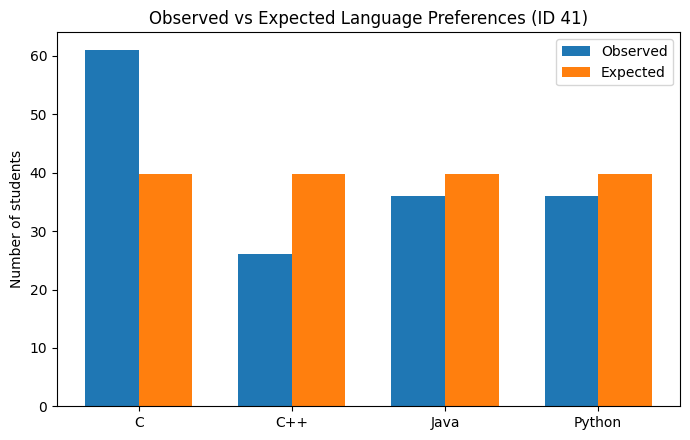

In [10]:

languages = ["C", "C++", "Java", "Python"]
x = np.arange(len(languages))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.bar(x - width / 2, observed, width, label='Observed')
ax.bar(x + width / 2, expected, width, label='Expected')

ax.set_xticks(x)
ax.set_xticklabels(languages)
ax.set_ylabel('Number of students')
ax.set_title('Observed vs Expected Language Preferences (ID 41)')
ax.legend()

fig.tight_layout()
fig.savefig('Chi_Square_ID_41_Observed_vs_Expected.png', dpi=300)
plt.show()
